# Imports e configuração

In [1]:
from pathlib import Path
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from statsmodels.tsa.holtwinters import ExponentialSmoothing

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", palette="muted")

ROOT = Path.cwd()
if not (ROOT / "data" / "sample").exists():
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data" / "sample"
REPORT_DIR = ROOT / "reports"
REPORT_DIR.mkdir(exist_ok=True)

FACT_PATH = DATA_DIR / "fact_demand_pricing_daily.parquet"

## Carregar e ordenar a base

In [2]:
fact = pd.read_parquet(FACT_PATH)
fact["date"] = pd.to_datetime(fact["date"])

fact = fact.sort_values(
    ["product_id", "region_id", "date"]
).reset_index(drop=True)

print(f"Linhas: {len(fact):,}")
print(f"Colunas: {fact.shape[1]}")
print(f"Período: {fact['date'].min().date()} a {fact['date'].max().date()}")
print(f"Produtos: {fact['product_id'].nunique()}")
print(f"Regiões: {fact['region_id'].nunique()}")

Linhas: 43,860
Colunas: 39
Período: 2024-01-01 a 2025-12-31
Produtos: 12
Regiões: 5


# Entendimento das Partições Temporais

In [3]:
split_summary = fact.groupby("dataset_split").agg(
    min_date=("date", "min"),
    max_date=("date", "max"),
    rows=("date", "size"),
)

split_summary

assert split_summary.loc["train", "max_date"] < split_summary.loc["validation", "min_date"]
assert split_summary.loc["validation", "max_date"] < split_summary.loc["test", "min_date"]

# Definição de alvo e Features

In [4]:
target = "units_sold"

numeric_features = [
    "year",
    "month",
    "quarter",
    "week_of_year",
    "day_of_week",
    "is_weekend",
    "is_holiday",
    "promo_flag",
    "discount_pct",
    "gross_unit_price_brl",
    "net_unit_price_brl",
    "relative_price_index",
    "available_stock_units",
    "lag_1_units",
    "lag_7_units",
    "rolling_7d_units",
    "rolling_28d_units",
    "trend_index",
]

categorical_features = [
    "product_id",
    "region_id",
    "category",
    "abc_class",
]

features = numeric_features + categorical_features

required_columns = features + [target, "date", "dataset_split"]
missing = sorted(set(required_columns) - set(fact.columns))
assert not missing, f"Colunas ausentes: {missing}"

# Separação de Treino, Validação e Teste

In [5]:
train = fact.loc[fact["dataset_split"] == "train"].copy()
validation = fact.loc[fact["dataset_split"] == "validation"].copy()
test = fact.loc[fact["dataset_split"] == "test"].copy()

print(train.shape, validation.shape, test.shape)

(21960, 39) (10860, 39) (11040, 39)


# Métricas de Avaliação

In [6]:
def wape(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    denominator = np.abs(y_true).sum()
    if denominator == 0:
        return np.nan
    return np.abs(y_true - y_pred).sum() / denominator


def evaluate_predictions(data, target_col="units_sold", prediction_col="prediction"):
    y_true = data[target_col].to_numpy()
    y_pred = data[prediction_col].to_numpy()

    return {
        "wape": wape(y_true, y_pred),
        "mae": mean_absolute_error(y_true, y_pred),
        "rmse": np.sqrt(mean_squared_error(y_true, y_pred)),
        "observations": len(data),
        "actual_units": y_true.sum(),
    }

# Baseline sazonal 7 Dias

In [7]:
baseline = fact.copy()
baseline = baseline.sort_values(["product_id", "region_id", "date"])

baseline["prediction_seasonal_7d"] = (
    baseline.groupby(["product_id", "region_id"])["units_sold"]
    .shift(7)
)

baseline_eval = baseline.loc[
    (baseline["dataset_split"] == "test") &
    (baseline["prediction_seasonal_7d"].notna())
].copy()

baseline_metrics = evaluate_predictions(
    baseline_eval,
    target_col="units_sold",
    prediction_col="prediction_seasonal_7d",
)

baseline_metrics

{'wape': np.float64(0.3504531722054381),
 'mae': 0.30471014492753623,
 'rmse': np.float64(0.5975493430598885),
 'observations': 11040,
 'actual_units': np.int64(9599)}

# Preparação de Pré-Processamento

In [8]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features),
])

X_train = train[features]
y_train = train[target]

X_validation = validation[features]
y_validation = validation[target]

X_test = test[features]
y_test = test[target]

## Regressão Ridge

In [9]:
ridge_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=10.0)),
])

start = time.perf_counter()
ridge_model.fit(X_train, y_train)
train_seconds = time.perf_counter() - start

validation["prediction"] = np.clip(ridge_model.predict(X_validation), 0, None)
validation_metrics_ridge = evaluate_predictions(validation)
validation_metrics_ridge["fit_seconds"] = train_seconds
validation_metrics_ridge

ridge_test = test.copy()
ridge_test["prediction"] = np.clip(ridge_model.predict(X_test), 0, None)
ridge_test_metrics = evaluate_predictions(ridge_test)
ridge_test_metrics

{'wape': np.float64(0.45322661199857645),
 'mae': 0.3940690442549217,
 'rmse': np.float64(0.5322518886990084),
 'observations': 11040,
 'actual_units': np.int64(9599)}

# Random Forest

In [10]:
rf_preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

rf_model = Pipeline([
    ("preprocessor", rf_preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=250,
        max_depth=14,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1,
    )),
])

start = time.perf_counter()
rf_model.fit(X_train, y_train)
rf_fit_seconds = time.perf_counter() - start

validation_rf = validation.copy()
validation_rf["prediction"] = np.clip(rf_model.predict(X_validation), 0, None)
rf_validation_metrics = evaluate_predictions(validation_rf)
rf_validation_metrics["fit_seconds"] = rf_fit_seconds
rf_validation_metrics

rf_test = test.copy()
rf_test["prediction"] = np.clip(rf_model.predict(X_test), 0, None)
rf_test_metrics = evaluate_predictions(rf_test)
rf_test_metrics

rf_configs = [
    {"n_estimators": 150, "max_depth": 10, "min_samples_leaf": 3},
    {"n_estimators": 250, "max_depth": 14, "min_samples_leaf": 3},
    {"n_estimators": 300, "max_depth": 20, "min_samples_leaf": 2},
]

# Modelo Temporal com Exponential Smoothing

Previsão Por Série

In [11]:
def temporal_forecast(train_frame, forecast_frame):
    train_frame = train_frame.sort_values("date")
    forecast_frame = forecast_frame.sort_values("date")

    y = train_frame.set_index("date")["units_sold"].asfreq("D")
    y = y.fillna(0)

    try:
        model = ExponentialSmoothing(
            y,
            trend="add",
            seasonal="add",
            seasonal_periods=7,
            initialization_method="estimated",
        )
        fitted = model.fit(optimized=True, use_brute=True)
        forecast = fitted.forecast(len(forecast_frame))
        forecast = np.clip(np.asarray(forecast), 0, None)
    except Exception:
        # Fallback robusto para séries curtas ou com erro de convergência.
        last_week = y.tail(7).to_numpy()
        if len(last_week) == 0:
            forecast = np.zeros(len(forecast_frame))
        else:
            forecast = np.resize(last_week, len(forecast_frame))

    result = forecast_frame[["date", "product_id", "region_id"]].copy()
    result["prediction"] = forecast
    return result

Previsão de Validação

In [12]:
temporal_validation_parts = []

for (product_id, region_id), train_group in train.groupby(["product_id", "region_id"]):
    validation_group = validation[
        (validation["product_id"] == product_id) &
        (validation["region_id"] == region_id)
    ]

    if len(validation_group) > 0:
        temporal_validation_parts.append(
            temporal_forecast(train_group, validation_group)
        )

temporal_validation = pd.concat(temporal_validation_parts, ignore_index=True)
temporal_validation = temporal_validation.merge(
    validation[["date", "product_id", "region_id", "units_sold"]],
    on=["date", "product_id", "region_id"],
    how="left",
)

temporal_validation_metrics = evaluate_predictions(temporal_validation)
temporal_validation_metrics

{'wape': np.float64(0.4989566392678891),
 'mae': 0.389471034168867,
 'rmse': np.float64(0.5449647011755424),
 'observations': 10860,
 'actual_units': np.int64(8477)}

# Previsão de Teste sem usar-lo durante a seleção

In [13]:
train_validation = pd.concat([train, validation], ignore_index=True)
temporal_test_parts = []

for (product_id, region_id), history_group in train_validation.groupby(["product_id", "region_id"]):
    test_group = test[
        (test["product_id"] == product_id) &
        (test["region_id"] == region_id)
    ]

    if len(test_group) > 0:
        temporal_test_parts.append(
            temporal_forecast(history_group, test_group)
        )

temporal_test = pd.concat(temporal_test_parts, ignore_index=True)
temporal_test = temporal_test.merge(
    test[["date", "product_id", "region_id", "units_sold"]],
    on=["date", "product_id", "region_id"],
    how="left",
)

temporal_test_metrics = evaluate_predictions(temporal_test)
temporal_test_metrics

{'wape': np.float64(0.3312305144542237),
 'mae': 0.28799653154403015,
 'rmse': np.float64(0.4459953561374923),
 'observations': 11040,
 'actual_units': np.int64(9599)}

# Comparação de Modelos em Validação

In [19]:
validation_results = pd.DataFrame([
    {
        "model": "seasonal_naive_7d",
        "split": "validation",
        **evaluate_predictions(
            baseline.loc[
                (baseline["dataset_split"] == "validation") &
                baseline["prediction_seasonal_7d"].notna()
            ].rename(columns={"prediction_seasonal_7d": "prediction"})
        ),
    },
    {
        "model": "ridge",
        "split": "validation",
        **validation_metrics_ridge,
    },
    {
        "model": "random_forest",
        "split": "validation",
        **rf_validation_metrics,
    },
    {
        "model": "exponential_smoothing",
        "split": "validation",
        **temporal_validation_metrics,
    },
])

validation_results.sort_values("wape")

,model,split,wape,mae,rmse,observations,actual_units,fit_seconds
2,random_forest,validation,0.3079,0.2403,0.3501,10860,8477,5.2170
0,seasonal_naive_7d,validation,0.3567,0.2785,0.5585,10860,8477,NaN
1,ridge,validation,0.4728,0.3690,0.5063,10860,8477,0.1569
3,exponential_smoothing,validation,0.4990,0.3895,0.5450,10860,8477,NaN


# Avaliação por Produto e Região

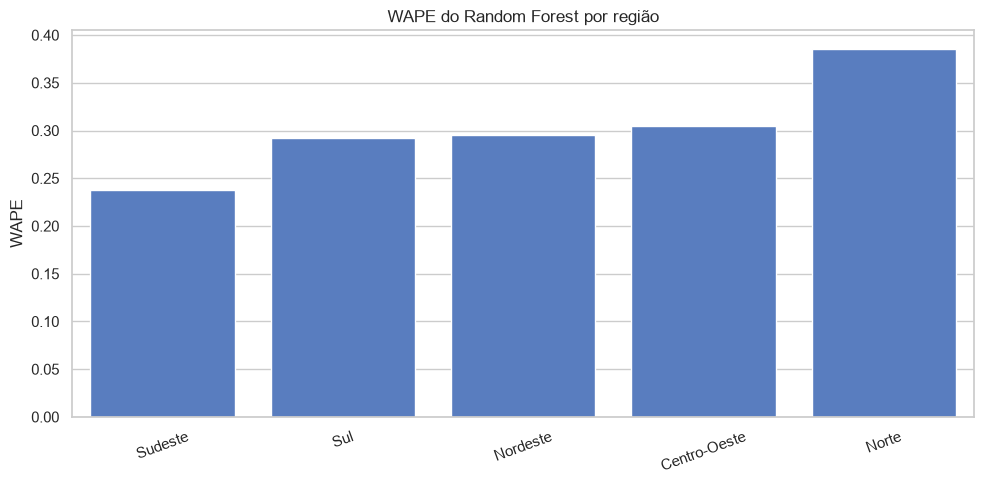

In [23]:
def evaluate_by_group(data, group_cols):
    rows = []

    for group_values, group in data.groupby(group_cols):
        if not isinstance(group_values, tuple):
            group_values = (group_values,)

        metrics = evaluate_predictions(group)
        row = dict(zip(group_cols, group_values))
        row.update(metrics)
        rows.append(row)

    return pd.DataFrame(rows)


def evaluate_by_group(data, group_cols):
    rows = []

    for group_values, group in data.groupby(group_cols):
        if not isinstance(group_values, tuple):
            group_values = (group_values,)

        metrics = evaluate_predictions(group)
        row = dict(zip(group_cols, group_values))
        row.update(metrics)
        rows.append(row)

    return pd.DataFrame(rows)

rf_test_segment = test.copy()
rf_test_segment["prediction"] = np.clip(rf_model.predict(X_test), 0, None)

rf_by_product = evaluate_by_group(rf_test_segment, ["product_id", "product_name"])
rf_by_region = evaluate_by_group(rf_test_segment, ["region_id", "region_name"])
rf_by_category = evaluate_by_group(rf_test_segment, ["category"])

rf_by_product.sort_values("wape", ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(data=rf_by_region.sort_values("wape"), x="region_name", y="wape")
plt.title("WAPE do Random Forest por região")
plt.ylabel("WAPE")
plt.xlabel("")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Curva Real vs Previsão

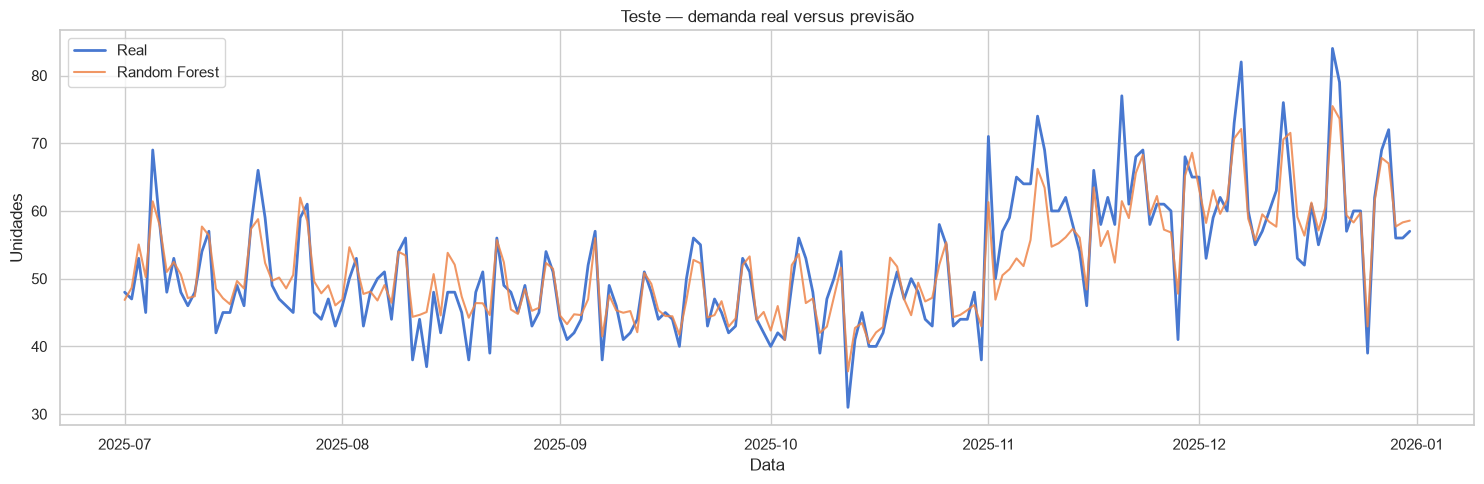

In [24]:
plot_data = test.copy()
plot_data["prediction_rf"] = np.clip(rf_model.predict(X_test), 0, None)

plot_daily = plot_data.groupby("date", as_index=False).agg(
    actual=("units_sold", "sum"),
    prediction_rf=("prediction_rf", "sum"),
)

plt.figure(figsize=(15, 5))
plt.plot(plot_daily["date"], plot_daily["actual"], label="Real", linewidth=2)
plt.plot(plot_daily["date"], plot_daily["prediction_rf"], label="Random Forest", alpha=0.85)
plt.title("Teste — demanda real versus previsão")
plt.xlabel("Data")
plt.ylabel("Unidades")
plt.legend()
plt.tight_layout()
plt.show()

# Experimentos

In [26]:
experiment_columns = [
    "experiment_id",
    "run_date",
    "model",
    "feature_set",
    "split",
    "parameters",
    "wape",
    "mae",
    "rmse",
    "observations",
    "fit_seconds",
    "notes",
]

experiments = pd.DataFrame(columns=experiment_columns)

from datetime import datetime


def add_experiment(
    experiments,
    experiment_id,
    model,
    feature_set,
    split,
    metrics,
    parameters,
    notes="",
):
    row = {
        "experiment_id": experiment_id,
        "run_date": datetime.now().isoformat(timespec="seconds"),
        "model": model,
        "feature_set": feature_set,
        "split": split,
        "parameters": json.dumps(parameters, ensure_ascii=False),
        "wape": metrics.get("wape"),
        "mae": metrics.get("mae"),
        "rmse": metrics.get("rmse"),
        "observations": metrics.get("observations"),
        "fit_seconds": metrics.get("fit_seconds"),
        "notes": notes,
    }
    return pd.concat([experiments, pd.DataFrame([row])], ignore_index=True)

In [27]:
experiments = add_experiment(
    experiments,
    experiment_id="exp_001",
    model="seasonal_naive_7d",
    feature_set="lag_7",
    split="validation",
    metrics=validation_results.loc[
        validation_results["model"] == "seasonal_naive_7d"
    ].iloc[0].to_dict(),
    parameters={"lag_days": 7},
    notes="Baseline sazonal semanal.",
)

experiments = add_experiment(
    experiments,
    experiment_id="exp_002",
    model="ridge",
    feature_set="calendar_price_lags",
    split="validation",
    metrics=validation_metrics_ridge,
    parameters={"alpha": 10.0},
    notes="Regressão linear regularizada.",
)

experiments = add_experiment(
    experiments,
    experiment_id="exp_003",
    model="random_forest",
    feature_set="calendar_price_lags",
    split="validation",
    metrics=rf_validation_metrics,
    parameters={
        "n_estimators": 250,
        "max_depth": 14,
        "min_samples_leaf": 3,
        "random_state": 42,
    },
    notes="Árvore ensemble não linear.",
)

experiments = add_experiment(
    experiments,
    experiment_id="exp_004",
    model="exponential_smoothing",
    feature_set="historical_series",
    split="validation",
    metrics=temporal_validation_metrics,
    parameters={
        "trend": "add",
        "seasonal": "add",
        "seasonal_periods": 7,
    },
    notes="Modelo temporal por série produto-região.",
)

experiments.to_csv(REPORT_DIR / "experiments.csv", index=False, encoding="utf-8")
experiments

,experiment_id,run_date,model,feature_set,split,parameters,wape,mae,rmse,observations,fit_seconds,notes
0,exp_001,2026-10-13T16:12:22,seasonal_naive_7d,lag_7,validation,"{""lag_days"": 7}",0.3567,0.2785,0.5585,10860,NaN,Baseline sazonal semanal.
1,exp_002,2026-10-13T16:12:22,ridge,calendar_price_lags,validation,"{""alpha"": 10.0}",0.4728,0.3690,0.5063,10860,0.1569,Regressão linear regularizada.
2,exp_003,2026-10-13T16:12:22,random_forest,calendar_price_lags,validation,"{""n_estimators"": 250, ""max_depth"": 14, ""min_sa...",0.3079,0.2403,0.3501,10860,5.2170,Árvore ensemble não linear.
3,exp_004,2026-10-13T16:12:22,exponential_smoothing,historical_series,validation,"{""trend"": ""add"", ""seasonal"": ""add"", ""seasonal_...",0.4990,0.3895,0.5450,10860,None,Modelo temporal por série produto-região.


# Teste Final

In [28]:
train_validation = pd.concat([train, validation], ignore_index=True)

X_train_validation = train_validation[features]
y_train_validation = train_validation[target]

final_rf_model = Pipeline([
    ("preprocessor", rf_preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=250,
        max_depth=14,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1,
    )),
])

final_rf_model.fit(X_train_validation, y_train_validation)

final_test = test.copy()
final_test["prediction"] = np.clip(
    final_rf_model.predict(test[features]),
    0,
    None,
)

final_test_metrics = evaluate_predictions(final_test)
final_test_metrics

{'wape': np.float64(0.30927667775441986),
 'mae': 0.2689082273337569,
 'rmse': np.float64(0.37167083766990455),
 'observations': 11040,
 'actual_units': np.int64(9599)}

# Backtesting com janelas temporais

In [29]:
cutoffs = [
    pd.Timestamp("2024-09-30"),
    pd.Timestamp("2024-12-31"),
    pd.Timestamp("2025-03-31"),
]

for cutoff in cutoffs:
    train_window = fact[fact["date"] <= cutoff].copy()
    validation_window = fact[
        (fact["date"] > cutoff) &
        (fact["date"] <= cutoff + pd.Timedelta(days=28))
    ].copy()

    print(
        cutoff.date(),
        len(train_window),
        len(validation_window),
    )

2024-09-30 16440 1680
2024-12-31 21960 1680
2025-03-31 27360 1680


# Diagnóstico de vazamento temporal

In [30]:
# Nenhuma feature histórica deve usar venda futura.
assert "units_sold" not in features
assert "revenue_brl" not in features
assert "gross_margin_brl" not in features

# As médias móveis são defasadas no dataset entregue.
assert "rolling_7d_units" in features
assert "rolling_28d_units" in features

# As partições não se sobrepõem temporalmente.
assert train["date"].max() < validation["date"].min()
assert validation["date"].max() < test["date"].min()

# Exportação de Previsões e Métricas

In [31]:
OUTPUT_DIR = REPORT_DIR / "trilha_b"
OUTPUT_DIR.mkdir(exist_ok=True)

final_test[
    [
        "date",
        "product_id",
        "region_id",
        "units_sold",
        "prediction",
        "promo_flag",
        "stockout_flag",
    ]
].to_parquet(OUTPUT_DIR / "predictions_test.parquet", index=False)

final_test[
    [
        "date",
        "product_id",
        "region_id",
        "units_sold",
        "prediction",
        "promo_flag",
        "stockout_flag",
    ]
].to_csv(OUTPUT_DIR / "predictions_test.csv", index=False)

experiments.to_csv(OUTPUT_DIR / "experiments.csv", index=False)
rf_by_product.to_csv(OUTPUT_DIR / "metrics_by_product.csv", index=False)
rf_by_region.to_csv(OUTPUT_DIR / "metrics_by_region.csv", index=False)